In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload the dataset
from google.colab import files
uploaded = files.upload()

# Read the CSV file
df = pd.read_csv('social_media_engagement_5000.csv')

# Display first five rows
print("SOCIAL MEDIA ENGAGEMENT DATASET")
display(df.head())

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

Saving social_media_engagement_5000.csv to social_media_engagement_5000 (1).csv
SOCIAL MEDIA ENGAGEMENT DATASET


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372



Dataset Shape:
(5000, 19)

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


In [3]:
# Check missing values using isnull()
print("Missing Values:")
print(df.isnull().sum())

# Check missing values using isna()
print("\nMissing Values using isna():")
print(df.isna().sum())

# Total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Missing Values using isna():
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Total Missing V

In [4]:
# Create a copy of the original dataset
df_clean = df.copy()

# Fill numerical missing values using median
numeric_columns = ['age', 'likes', 'comments', 'shares']

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# Fill categorical missing values using mode
categorical_columns = ['gender', 'sentiment']

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].mode()[0])

# Check missing values after cleaning
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nTotal Missing Values:")
print(df_clean.isnull().sum().sum())

Missing Values After Cleaning:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

Total Missing Values:
0


In [5]:
# Check duplicate rows
print("Number of Duplicate Rows:")
print(df_clean.duplicated().sum())

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Check duplicates after removal
print("\nDuplicates After Cleaning:")
print(df_clean.duplicated().sum())

# Display updated dataset shape
print("\nUpdated Dataset Shape:")
print(df_clean.shape)

Number of Duplicate Rows:
0

Duplicates After Cleaning:
0

Updated Dataset Shape:
(5000, 19)


In [6]:
df_clean['posted_at'] = pd.to_datetime(df_clean['posted_at'], errors='coerce')

df_clean['gender'] = df_clean['gender'].str.strip().str.lower()
df_clean['sentiment'] = df_clean['sentiment'].str.strip().str.lower()
df_clean['post_type'] = df_clean['post_type'].str.strip().str.lower()
df_clean['category'] = df_clean['category'].str.strip().str.lower()
df_clean['country'] = df_clean['country'].str.strip().str.title()
df_clean['device'] = df_clean['device'].str.strip().str.lower()

print(df_clean.dtypes)

/tmp/ipykernel_1924/1822792569.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_clean['posted_at'] = pd.to_datetime(df_clean['posted_at'], errors='coerce')


KeyError: 'category'

In [7]:
df_clean['posted_at'] = pd.to_datetime(df_clean['posted_at'], errors='coerce')

df_clean['gender'] = df_clean['gender'].str.strip().str.lower()
df_clean['sentiment'] = df_clean['sentiment'].str.strip().str.lower()
df_clean['post_type'] = df_clean['post_type'].str.strip().str.lower()
df_clean['post_category'] = df_clean['post_category'].str.strip().str.lower()
df_clean['country'] = df_clean['country'].str.strip().str.title()
df_clean['device_type'] = df_clean['device_type'].str.strip().str.lower()

print(df_clean.dtypes)

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object


In [8]:
df_clean['sentiment'] = df_clean['sentiment'].str.lower().str.strip()

df_clean['hashtags'] = df_clean['hashtags'].fillna('')

df_clean['hashtag_count'] = df_clean['hashtags'].apply(
    lambda x: len([tag for tag in x.split() if tag.startswith('#')])
)

df_clean[['hashtags', 'hashtag_count', 'sentiment']].head()

,hashtags,hashtag_count,sentiment
0,#foodie #travel #love,3,negative
1,#fitness,1,negative
2,#foodie,1,positive
3,#music #foodie #fun,3,negative
4,#travel,1,negative


In [9]:
df_clean['posted_at'] = pd.to_datetime(df_clean['posted_at'], format='%d-%m-%Y', errors='coerce')

df_clean['age'] = df_clean['age'].clip(lower=13, upper=100)

for column in ['likes', 'comments', 'shares']:
    df_clean[column] = df_clean[column].clip(lower=0)

df_clean['sentiment'] = df_clean['sentiment'].str.lower().str.strip()
df_clean['hashtags'] = df_clean['hashtags'].fillna('').str.lower().str.strip()

df_clean['hashtag_count'] = df_clean['hashtags'].apply(
    lambda x: x.count('#')
)

print(df_clean.head())
print(df_clean.dtypes)

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  female      Uk   109864      text          food   4862.0   
3    64886  51.0   other  France   848877      text       fitness   5350.0   
4    16265  34.0   other      Uk   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile 

In [10]:
print("First 5 Rows:")
display(df_clean.head())

print("Last 5 Rows:")
display(df_clean.tail())

print("Dataset Shape:")
print(df_clean.shape)

print("Column Names:")
print(df_clean.columns)

print("Dataset Information:")
df_clean.info()

print("Summary Statistics:")
display(df_clean.describe())

First 5 Rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,Uk,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,Uk,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


Last 5 Rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,Uae,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,Usa,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


Dataset Shape:
(5000, 20)
Column Names:
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')
Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes       

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [11]:
categorical_columns = df_clean.select_dtypes(include='object').columns

for column in categorical_columns:
    print("\n", column)
    print("Unique Values:", df_clean[column].unique())
    print("Number of Unique Values:", df_clean[column].nunique())
    print(df_clean[column].value_counts())


 gender
Unique Values: ['female' 'male' 'other']
Number of Unique Values: 3
gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

 country
Unique Values: ['Brazil' 'Uk' 'France' 'Canada' 'Japan' 'Australia' 'India' 'Uae'
 'Germany' 'Usa']
Number of Unique Values: 10
country
India        535
Canada       513
Brazil       504
Uae          503
Usa          501
France       496
Uk           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64

 post_type
Unique Values: ['image' 'reel' 'text' 'video']
Number of Unique Values: 4
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

 post_category
Unique Values: ['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']
Number of Unique Values: 8
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

 device_type

In [12]:
numeric_columns = df_clean.select_dtypes(include='number')

correlation_matrix = numeric_columns.corr()

display(correlation_matrix)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [13]:
print("Average Likes by Post Type:")
display(df_clean.groupby('post_type')['likes'].mean().sort_values(ascending=False))

print("Average Impressions by Country:")
display(df_clean.groupby('country')['impressions'].mean().sort_values(ascending=False))

print("Average Engagement Rate by Sentiment:")
display(df_clean.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False))

Average Likes by Post Type:


,likes
post_type,
video,10188.600000
image,10104.865277
text,10100.148193
reel,10037.802416


Average Impressions by Country:


KeyError: 'Column not found: impressions'

In [14]:
print(df_clean.columns.tolist())


['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


In [15]:
print("Average Likes by Post Type:")
display(df_clean.groupby('post_type')['likes'].mean().sort_values(ascending=False))

print("Average Impressions by Country:")
display(df_clean.groupby('country')['impression_count'].mean().sort_values(ascending=False))

print("Average Engagement Rate by Sentiment:")
display(df_clean.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False))

Average Likes by Post Type:


,likes
post_type,
video,10188.600000
image,10104.865277
text,10100.148193
reel,10037.802416


Average Impressions by Country:


,impression_count
country,
India,52462.386916
France,51727.673387
Usa,51263.872255
Uk,51119.393509
Japan,49616.135593
Brazil,49193.174603
Uae,48928.413519
Canada,48703.150097
Germany,48605.406122


Average Engagement Rate by Sentiment:


,engagement_rate
sentiment,
negative,1.038486
neutral,0.991170
positive,0.919744


In [16]:
import numpy as np

df_clean['engagement_score'] = df_clean['likes'] + df_clean['comments'] + df_clean['shares']

df_clean['log_likes'] = np.log1p(df_clean['likes'])
df_clean['log_comments'] = np.log1p(df_clean['comments'])
df_clean['log_shares'] = np.log1p(df_clean['shares'])

display(df_clean[['likes', 'comments', 'shares', 'engagement_score', 'log_likes', 'log_comments', 'log_shares']].head())

,likes,comments,shares,engagement_score,log_likes,log_comments,log_shares
0,7011.0,354.0,1157.0,8522.0,8.855378,5.872118,7.054450
1,11750.0,2606.0,1807.0,16163.0,9.371694,7.865955,7.499977
2,4862.0,344.0,955.0,6161.0,8.489411,5.843544,6.862758
3,5350.0,1083.0,1049.0,7482.0,8.585039,6.988413,6.956545
4,12682.0,2735.0,1300.0,16717.0,9.448018,7.914252,7.170888


In [17]:
print("Post Type Analysis:")
display(df_clean.groupby('post_type')[['likes', 'comments', 'shares', 'engagement_score']].mean())

print("Country Analysis:")
display(df_clean.groupby('country')[['likes', 'comments', 'shares', 'engagement_score']].mean())

print("Sentiment Analysis:")
display(df_clean.groupby('sentiment')[['likes', 'comments', 'shares', 'engagement_score']].mean())

Post Type Analysis:


,likes,comments,shares,engagement_score
post_type,,,,
image,10104.865277,1525.235766,1019.289495,12649.390537
reel,10037.802416,1504.187062,982.042089,12524.031567
text,10100.148193,1499.106024,1013.989558,12613.243775
video,10188.600000,1479.160000,996.834286,12664.594286


Country Analysis:


,likes,comments,shares,engagement_score
country,,,,
Australia,10294.124746,1485.803245,1029.693712,12809.621704
Brazil,9886.689484,1490.434524,1008.859127,12385.983135
Canada,10063.066277,1546.582846,996.245614,12605.894737
France,10372.876008,1478.695565,1051.812500,12903.384073
Germany,10130.458163,1531.826531,973.379592,12635.664286
India,9962.468224,1494.917757,1035.315888,12492.701869
Japan,10088.862288,1530.434322,959.351695,12578.648305
Uae,10227.487078,1541.214712,989.075547,12757.777336
Uk,9935.650101,1463.042596,985.681542,12384.374239


Sentiment Analysis:


,likes,comments,shares,engagement_score
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,12731.498958
neutral,9923.194499,1528.404060,996.565160,12448.163720
positive,10180.062077,1480.650617,1005.086749,12665.799443


In [18]:
columns = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count']

for column in columns:
    print("\nStatistics for:", column)
    print("Mean:", df_clean[column].mean())
    print("Median:", df_clean[column].median())
    print("Mode:", df_clean[column].mode()[0])
    print("Standard Deviation:", df_clean[column].std())
    print("Variance:", df_clean[column].var())
    print("25th Percentile:", df_clean[column].quantile(0.25))
    print("50th Percentile:", df_clean[column].quantile(0.50))
    print("75th Percentile:", df_clean[column].quantile(0.75))


Statistics for: likes
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5
Standard Deviation: 5702.293017183876
Variance: 32516145.653823998
25th Percentile: 5235.0
50th Percentile: 10105.5
75th Percentile: 14959.0

Statistics for: comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0
Standard Deviation: 856.3933120458967
Variance: 733409.5049169405
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25

Statistics for: shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0
Standard Deviation: 570.8551999758862
Variance: 325875.65933950903
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0

Statistics for: watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916
Standard Deviation: 2308.096459042085
Variance: 5327309.26424261
25th Percentile: 2017.75
50th Percentile: 4034.5
75th Percentile: 6020.25

Statistics for: engagement_rate
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: 0.006362909
Standard Deviation: 5.318029222661535
Variance: 28.281434813082043

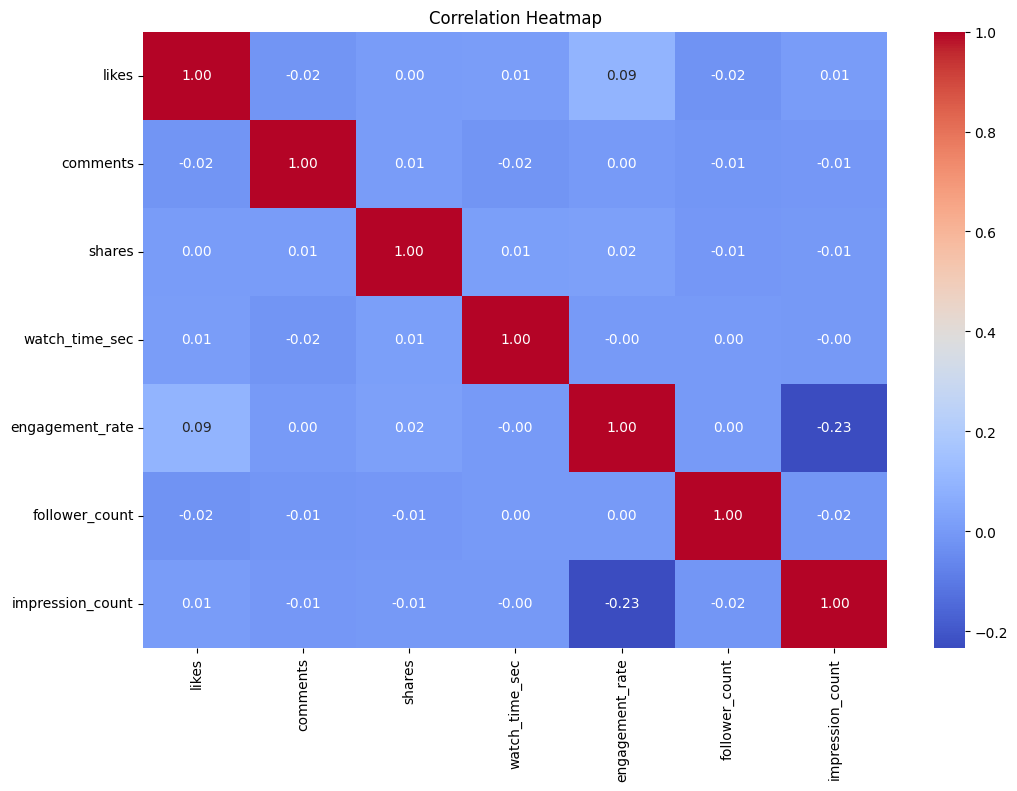

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count', 'impression_count']

plt.figure(figsize=(12, 8))
sns.heatmap(df_clean[numeric_columns].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

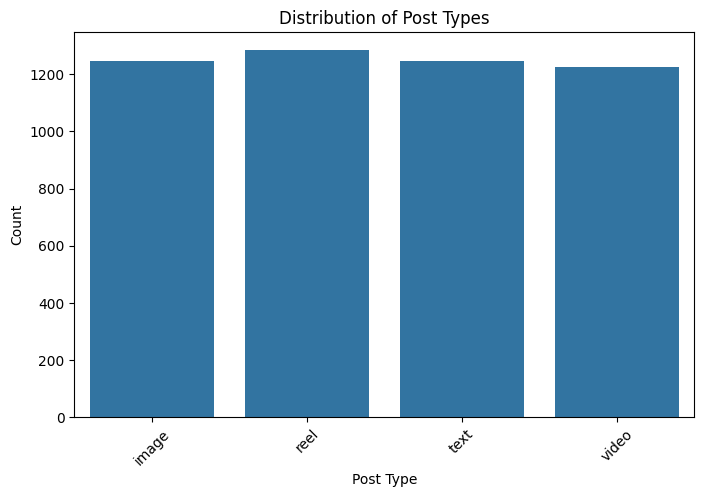

In [20]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='post_type')
plt.title('Distribution of Post Types')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

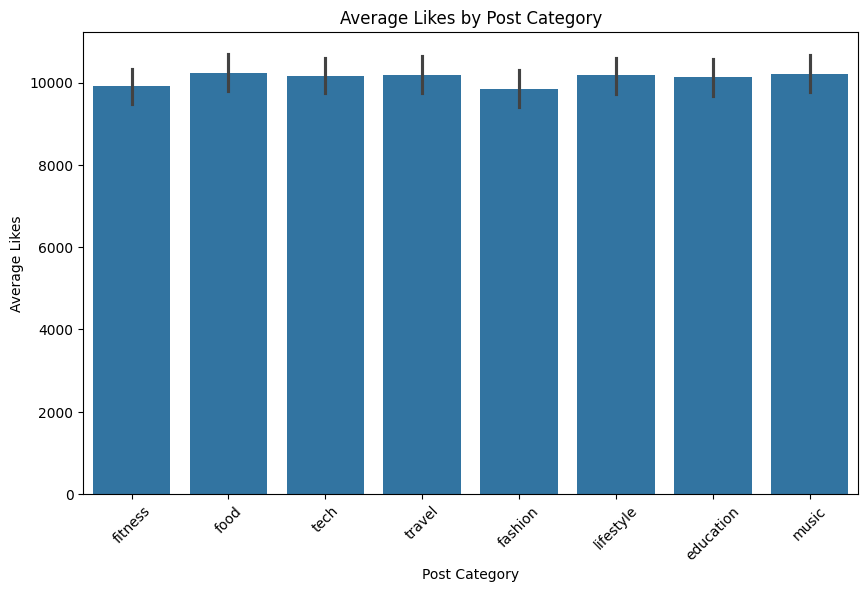

In [21]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df_clean, x='post_category', y='likes', estimator='mean')
plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)
plt.show()

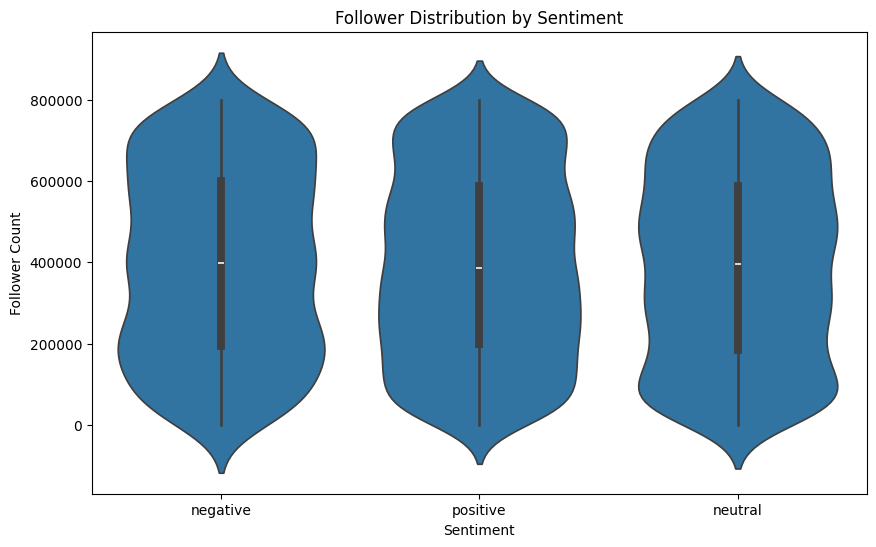

In [22]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_clean, x='sentiment', y='follower_count')
plt.title('Follower Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.show()

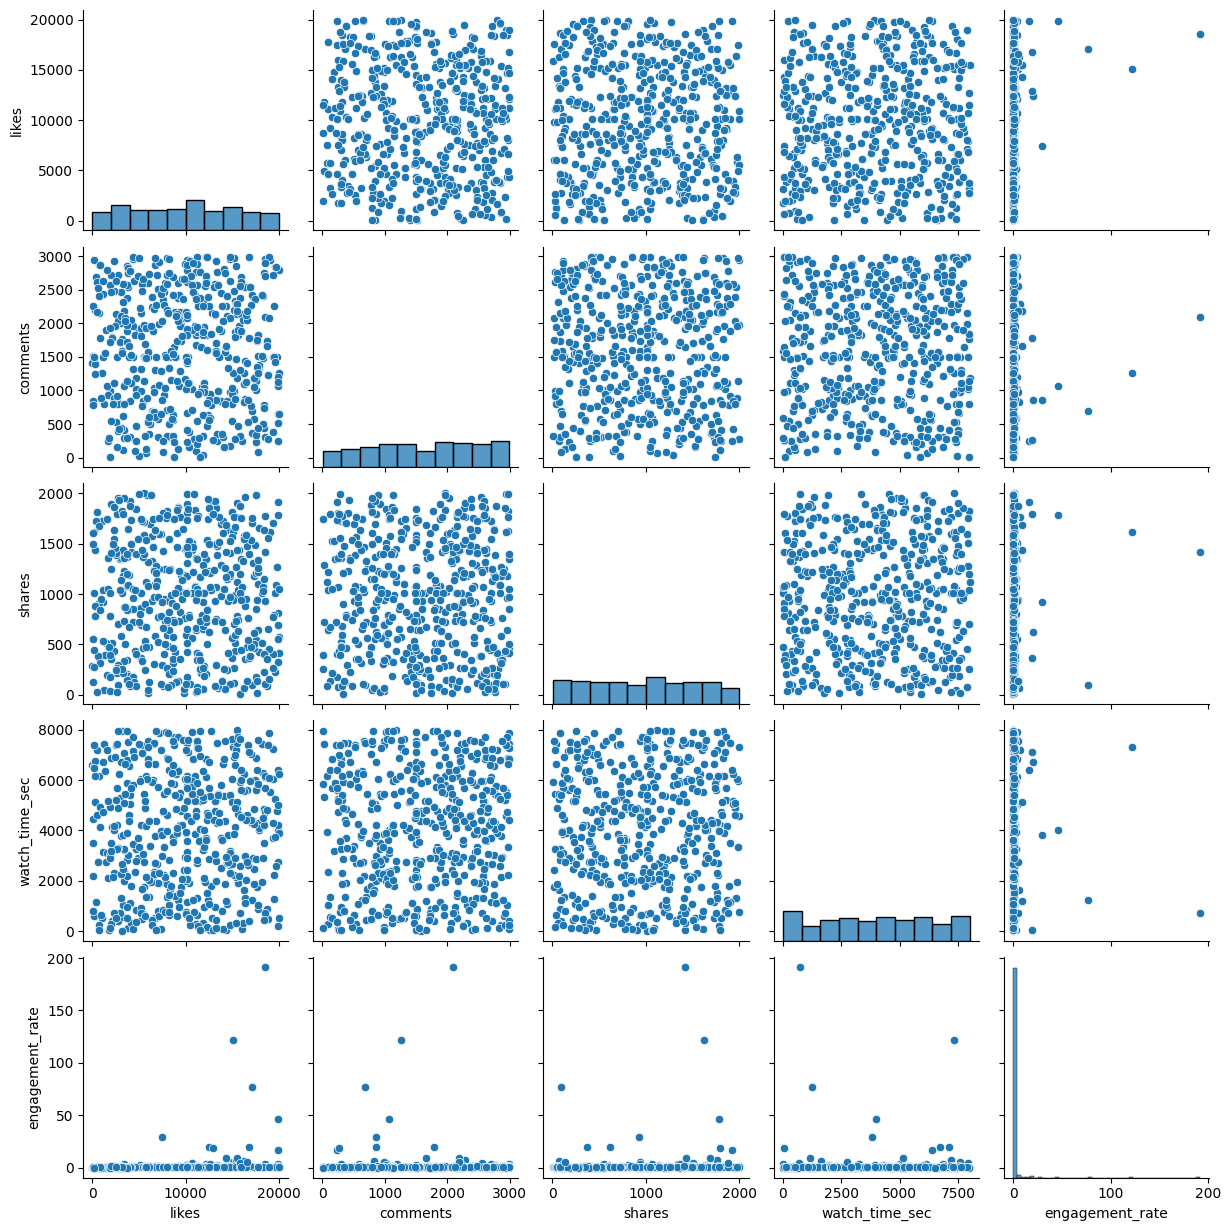

In [23]:
sns.pairplot(df_clean[['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate']].sample(500))
plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 44.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 52.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 60.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 55.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 62.6% of the points cannot be plac

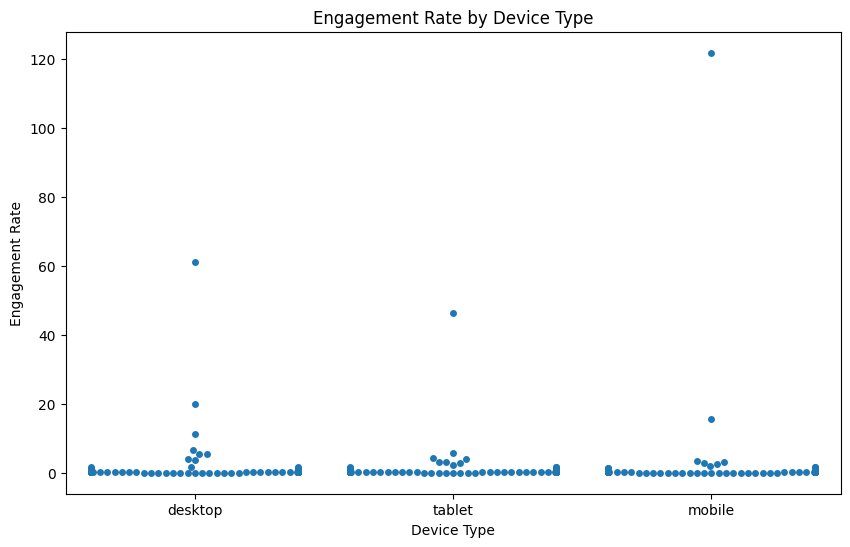

In [24]:
plt.figure(figsize=(10, 6))
sns.swarmplot(data=df_clean.sample(300), x='device_type', y='engagement_rate')
plt.title('Engagement Rate by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')
plt.show()

In [25]:
import plotly.express as px

daily_engagement = df_clean.groupby('posted_at')['engagement_rate'].mean().reset_index()

fig = px.line(daily_engagement, x='posted_at', y='engagement_rate',
              title='Daily Engagement Trend',
              labels={'posted_at': 'Date', 'engagement_rate': 'Average Engagement Rate'})

fig.show()

In [26]:
import plotly.express as px

post_engagement = df_clean.groupby('post_type')['likes'].mean().reset_index()

fig = px.bar(post_engagement, x='post_type', y='likes',
             title='Average Likes by Post Type',
             labels={'post_type': 'Post Type', 'likes': 'Average Likes'},
             text_auto=True)

fig.show()

In [27]:
fig = px.scatter(df_clean, x='impression_count', y='likes',
                 color='post_type',
                 size='engagement_rate',
                 hover_data=['country', 'sentiment'],
                 title='Likes vs Impressions by Post Type')

fig.show()

In [28]:
post_type_analysis = df_clean.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Post Type:")
print(post_type_analysis)

print("\nBest Performing Post Type:")
print(post_type_analysis.idxmax())

Average Engagement Rate by Post Type:
post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

Best Performing Post Type:
video


In [29]:
category_analysis = df_clean.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Category:")
print(category_analysis)

print("\nBest Performing Category:")
print(category_analysis.idxmax())

Average Engagement Rate by Category:
post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

Best Performing Category:
food


In [30]:
country_analysis = df_clean.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Country:")
print(country_analysis)

print("\nTop Performing Country:")
print(country_analysis.idxmax())

Average Engagement Rate by Country:
country
Brazil       1.540704
Australia    1.324339
France       1.146402
Uae          1.112352
Canada       0.916659
Uk           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
Usa          0.576580
Name: engagement_rate, dtype: float64

Top Performing Country:
Brazil


In [31]:
age_analysis = df_clean.groupby('age')['engagement_rate'].mean()

print("Average Engagement Rate by Age:")
print(age_analysis)

print("\nAge with Highest Engagement:")
print(age_analysis.idxmax())

Average Engagement Rate by Age:
age
13.0    0.455583
14.0    1.003067
15.0    0.714170
16.0    1.226848
17.0    0.858763
18.0    0.888391
19.0    0.676687
20.0    0.515541
21.0    0.452752
22.0    0.586786
23.0    0.922448
24.0    2.897327
25.0    1.041681
26.0    0.501467
27.0    0.775328
28.0    0.385081
29.0    1.110432
30.0    1.270129
31.0    0.440684
32.0    0.581710
33.0    1.277557
34.0    0.557236
35.0    1.521596
36.0    0.609569
37.0    0.494109
38.0    1.035114
39.0    0.436184
40.0    0.930504
41.0    1.540070
42.0    1.350772
43.0    0.566439
44.0    0.795102
45.0    0.513521
46.0    0.663994
47.0    1.402015
48.0    1.675878
49.0    0.999235
50.0    1.552627
51.0    2.397295
52.0    0.867426
53.0    0.707924
54.0    1.002622
55.0    2.599106
56.0    0.524008
57.0    0.919751
58.0    0.435130
59.0    0.495578
60.0    0.759586
61.0    0.553854
62.0    1.005127
63.0    1.303909
64.0    0.402533
Name: engagement_rate, dtype: float64

Age with Highest Engagement:
24.0


In [32]:
verified_analysis = df_clean.groupby('is_verified')['engagement_rate'].mean()

print("Average Engagement Rate:")
print(verified_analysis)

print("\nVerified Account Performance:")
print(verified_analysis)

Average Engagement Rate:
is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64

Verified Account Performance:
is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


In [33]:
df_clean['posted_at'] = pd.to_datetime(df_clean['posted_at'])

df_clean['post_hour'] = df_clean['posted_at'].dt.hour

time_analysis = df_clean.groupby('post_hour')['impression_count'].mean().sort_values(ascending=False)

print("Average Impressions by Hour:")
print(time_analysis)

print("\nBest Posting Hour:")
print(time_analysis.idxmax())

Average Impressions by Hour:
post_hour
0    50013.7328
Name: impression_count, dtype: float64

Best Posting Hour:
0


In [34]:
device_analysis = df_clean.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

print("Average Watch Time by Device:")
print(device_analysis)

print("\nBest Performing Device:")
print(device_analysis.idxmax())

Average Watch Time by Device:
device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

Best Performing Device:
mobile


In [35]:
sentiment_analysis = df_clean.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)

print("Average Engagement Rate by Sentiment:")
print(sentiment_analysis)

print("\nBest Performing Sentiment:")
print(sentiment_analysis.idxmax())

Average Engagement Rate by Sentiment:
sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64

Best Performing Sentiment:
negative


In [36]:
sentiment_details = df_clean[df_clean['sentiment'].isin(['negative', 'neutral'])]

sentiment_summary = sentiment_details.groupby('sentiment').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

print(sentiment_summary)

           average_likes  average_comments  average_shares  average_engagement
sentiment                                                                     
negative    10208.096875       1516.094792     1007.307292            1.038486
neutral      9923.194499       1528.404060      996.565160            0.991170


In [37]:
print("========== SOCIAL MEDIA ENGAGEMENT ANALYSIS ==========")

print("\n1. CONTENT PERFORMANCE")
print("Best Post Type:", post_type_analysis.idxmax())
print("Best Content Category:", category_analysis.idxmax())
print("Top Country:", country_analysis.idxmax())

print("\n2. USER TRENDS")
print("Age with Highest Engagement:", age_analysis.idxmax())
print("Verified Account Analysis:")
print(verified_analysis)

print("\n3. BEHAVIORAL INSIGHTS")
print("Best Posting Hour:", time_analysis.idxmax())
print("Best Performing Device:", device_analysis.idxmax())

print("\n4. SENTIMENT ANALYSIS")
print("Best Performing Sentiment:", sentiment_analysis.idxmax())
print("\nNegative and Neutral Sentiment:")
print(sentiment_summary)

print("\n========== ANALYSIS COMPLETED ==========")

========== SOCIAL MEDIA ENGAGEMENT ANALYSIS ==========

1. CONTENT PERFORMANCE
Best Post Type: video
Best Content Category: food
Top Country: Brazil

2. USER TRENDS
Age with Highest Engagement: 24.0
Verified Account Analysis:
is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64

3. BEHAVIORAL INSIGHTS
Best Posting Hour: 0
Best Performing Device: mobile

4. SENTIMENT ANALYSIS
Best Performing Sentiment: negative

Negative and Neutral Sentiment:
           average_likes  average_comments  average_shares  average_engagement
sentiment                                                                     
negative    10208.096875       1516.094792     1007.307292            1.038486
neutral      9923.194499       1528.404060      996.565160            0.991170

========== ANALYSIS COMPLETED ==========
